In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, classification_report
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

X_train = pd.read_csv('../data/processed/X_train.csv')
y_train = pd.read_csv('../data/processed/y_train.csv')['TARGET']
X_test  = pd.read_csv('../data/processed/X_test.csv')
y_test  = pd.read_csv('../data/processed/y_test.csv')['TARGET']
print('Loaded. Shape:', X_train.shape)

Loaded. Shape: (98403, 192)


In [2]:
# ── 5 diverse base models ──
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    'LogisticRegression': LogisticRegression(max_iter=2000, class_weight='balanced', solver='saga', random_state=42),
    'RandomForest':       RandomForestClassifier(n_estimators=200, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1),
    'GradientBoosting':   GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=5, random_state=42),
    'XGBoost':            XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=6, scale_pos_weight=scale_pos, random_state=42, eval_metric='logloss', verbosity=0),
    'LightGBM':           LGBMClassifier(n_estimators=200, learning_rate=0.05, max_depth=6, class_weight='balanced', random_state=42, verbose=-1),
}

base_probabilities = {}
for name, model in models.items():
    print(f'Training {name}...')
    model.fit(X_train, y_train)
    probs = model.predict_proba(X_test)[:, 1]
    base_probabilities[name] = probs
    auc = roc_auc_score(y_test, probs)
    print(f'  ROC AUC: {auc:.4f}')
    joblib.dump(model, f'../models/base/{name.lower()}.pkl')

pd.DataFrame(base_probabilities).to_csv('../notebooks/base_probabilities.csv', index=False)
print('All base models saved.')

Training LogisticRegression...


c:\Users\sharo\OneDrive\Documents\NMIMS\ML\credit-risk\venv\Lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


  ROC AUC: 0.7436
Training RandomForest...
  ROC AUC: 0.7310
Training GradientBoosting...
  ROC AUC: 0.7584
Training XGBoost...
  ROC AUC: 0.7515
Training LightGBM...
  ROC AUC: 0.7542
All base models saved.


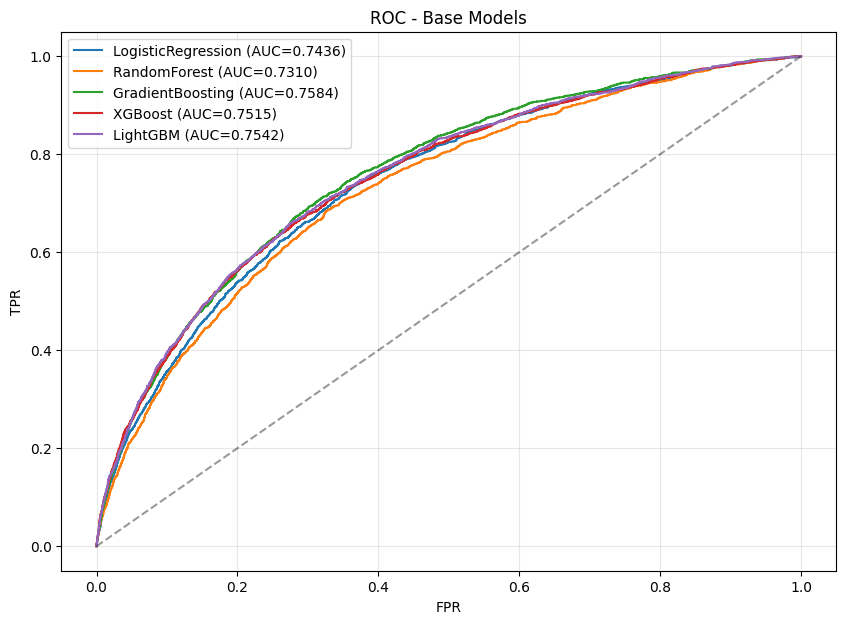

In [3]:
plt.figure(figsize=(10,7))
for name, probs in base_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.4f})')
plt.plot([0,1],[0,1],'k--',alpha=0.4)
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('ROC - Base Models')
plt.legend(); plt.grid(alpha=0.3)
plt.savefig('../reports/figures/03_base_models_roc.png', dpi=150, bbox_inches='tight')
plt.show()